# Module 2 – Illumination Correction (Elif Yeşilyurt, 240610008)

**Group project:** Image Enhancement in Licence Plate Recognition Systems (guideline topic 4).
**My module:** Correct uneven lighting (flash glare, shadows, darkness) on licence-plate crops before binarization (Module 3).

| Item | Content |
|---|---|
| Input | 50 perspective-rectified plate crops (440×140 px) from CCPD-DB |
| Methods compared (same crops) | Original (baseline) · CLAHE on LAB-L · CLAHE + Top-Hat/Black-Hat (report pipeline) · Homomorphic filtering on LAB-L |
| Expected output | Illumination-corrected crop of identical size/orientation |
| Primary metric | OCR Character Error Rate (Tesseract 5.5.4) vs. CCPD ground-truth plate text |
| Auxiliary measures | luminance mean/std, local contrast, illumination non-uniformity, saturation, chroma shift (not OCR evidence) |

**Data source:** CCPD (Chinese City Parking Dataset), Xu et al., ECCV 2018, pp. 255–271, https://github.com/detectRecog/CCPD — **MIT License** (Copyright (c) 2017 CCPD). Subset: `ccpd_db` (from `CCPD2019.tar.xz`).

> The crops are produced here from CCPD corner annotations as a **temporary** rectification. They are *not* Module 1's final output (Gül Berra Aslan). If Module 1 crops become available they should replace `results/crops/original/`.

This notebook **reads the results produced by `src/run_pipeline.py`** and re-demonstrates the methods on one crop. The README gives the command to regenerate everything.

In [1]:
import os, sys, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
PROJECT = os.path.abspath('.')
sys.path.insert(0, os.path.join(PROJECT, 'src'))
import module2 as m2
R = os.path.join(PROJECT, 'results')
plt.rcParams['font.family'] = ['Arial Unicode MS', 'Hiragino Sans GB', 'DejaVu Sans']
pd.set_option('display.width', 200)
print('OpenCV', cv2.__version__, '| numpy', np.__version__)

OpenCV 5.1.0 | numpy 2.0.2


## 1. Central configuration (exact values used in the reported run)

In [2]:
cfg = json.load(open(os.path.join(R, 'config_used.json')))
for k in ['crop', 'clahe', 'tophat', 'homomorphic', 'ocr']:
    print(k, '->', cfg[k])

crop -> {'width': 440, 'height': 140, 'interpolation': 'INTER_CUBIC', 'min_plate_width_px': 150, 'min_plate_height_px': 45}
clahe -> {'color_space': 'LAB', 'clip_limit': 2.0, 'tile_grid': [8, 2]}
tophat -> {'se_factor': 2.0, 'stroke_min': 3, 'stroke_max': 25, 'stroke_fallback_ratio': 0.07142857142857142, 'weight': 1.0}
homomorphic -> {'color_space': 'LAB', 'gamma_low': 0.5, 'gamma_high': 1.5, 'c': 1.0, 'd0': 10.0, 'pad': 'reflect', 'norm_percentiles': [0.5, 99.5]}
ocr -> {'engine': 'tesseract', 'lang': 'chi_sim', 'oem': 1, 'psm': 8, 'grayscale': True, 'whitelist': True, 'tessdata_dir': 'ocr/tessdata', 'calibration_seed': 7, 'calibration_n': 20}


## 2. Data: selection and ROI validation
* 30 candidates from `elif_ccpd_db_selection` (seed 42; 10 dark / 10 mid / 10 bright by **CCPD filename brightness metadata**).
* +20 seeded extension (seed 2026) to reach the group plan of **50 difficult-lighting images**.
* **Caveat:** in CCPD-DB the brightness metadata is bimodal (5–60 or 180–242, no values in between), so the 'mid' group (22–39) is the upper end of the dark mode, not a true middle level.
* Filename parsed exactly per the official README: area – tilt – bbox – 4 vertices (RB, LB, LT, RT) – plate indices – brightness – blurriness.

In [3]:
man = pd.read_csv(os.path.join(R, 'manifest_roi.csv'), keep_default_na=False)
print(open(os.path.join(R, 'selection_rule.txt')).read())
display(man.groupby(['group', 'roi_status']).size().rename('n').reset_index())
display(man[man.roi_status != 'ok'][['id', 'group', 'plate_w_px', 'plate_h_px', 'roi_status', 'roi_reason']])

Original 30 candidates: elif_ccpd_db_selection/manifest.csv (seed 42; 10 dark/10 mid/10 bright by CCPD filename brightness metadata).
Extension (20): random.Random(2026).sample over sorted ccpd_db filenames not in the 30-candidate list, ROI valid and plate width >= 150px; dark: brightness <= 21 (pool 2231), bright: brightness >= 204 (pool 1587)
Group labels use CCPD filename brightness metadata (plate-region brightness as annotated by CCPD), not a local light measurement.



,group,roi_status,n
0,bright,ok,20
1,dark,ok,18
2,dark,review_required,2
3,mid,ok,10


,id,group,plate_w_px,plate_h_px,roi_status,roi_reason
1,S02,dark,130.6,46.1,review_required,small plate (131x46px) upsampled to 440x140
3,S04,dark,133.2,43.4,review_required,small plate (133x43px) upsampled to 440x140


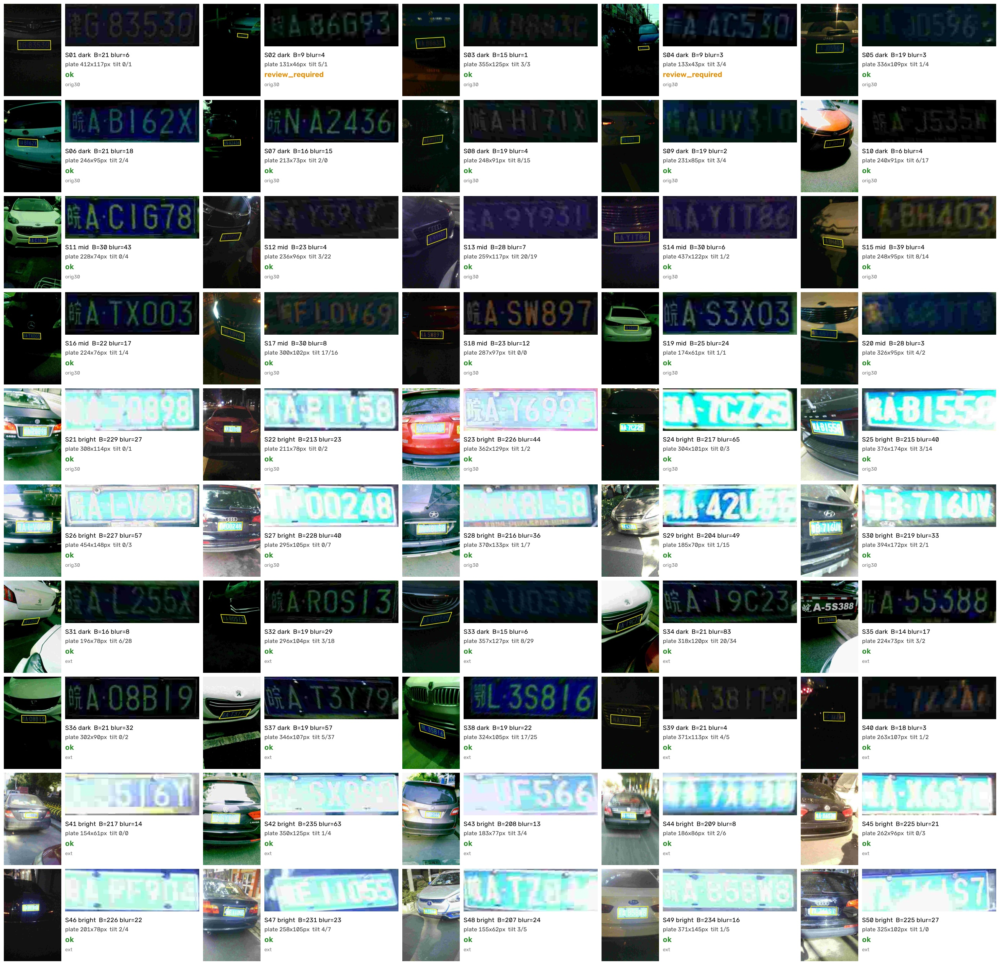

In [4]:
display(Image(os.path.join(R, 'figures/contact_sheet_roi.jpg'), width=1100))

## 3. Methods – live demonstration on one crop
* **CLAHE**: BGR→LAB, CLAHE on L only (a, b untouched → no hue change), clip limit 2.0, 8×2 tiles (≈55×70 px, larger than one character).
* **Top-Hat / Black-Hat** (as written in our report): L' = L + TopHat(L) − BlackHat(L) after CLAHE; elliptical SE of size 2× the stroke width estimated per crop with a distance transform.
* **Homomorphic**: f = i·r ⇒ ln f = ln i + ln r. log1p(L) → reflect-pad → FFT → Gaussian high-emphasis filter H = (γH−γL)[1−exp(−c·D²/D0²)] + γL with γL = 0.5 (illumination attenuated), γH = 1.5 (reflectance/edges boosted), D0 = 10 → inverse FFT → expm1 → robust 0.5–99.5 % normalisation. Applied to L only.

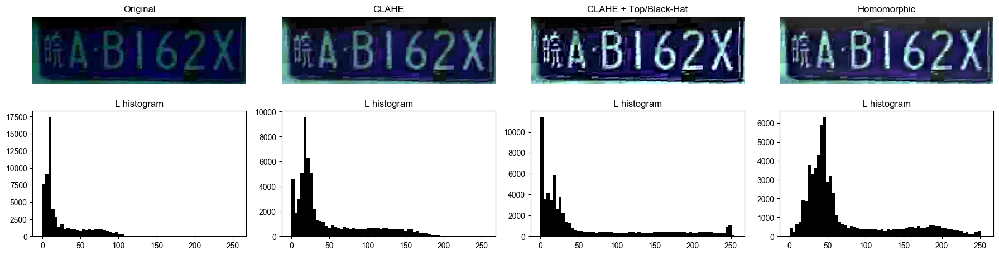

CLAHE identical to saved result: True
Homomorphic identical to saved result: True


In [5]:
crop = cv2.imread(os.path.join(R, 'crops/original/S06.png'))
variants = {'Original': crop, 'CLAHE': m2.apply_clahe(crop),
            'CLAHE + Top/Black-Hat': m2.apply_clahe_tophat(crop)[0], 'Homomorphic': m2.apply_homomorphic(crop)[0]}
fig, ax = plt.subplots(2, 4, figsize=(18, 5))
for j, (k, v) in enumerate(variants.items()):
    ax[0, j].imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(k); ax[0, j].axis('off')
    ax[1, j].hist(m2.luminance(v).ravel(), 64, (0, 255), color='k'); ax[1, j].set_title('L histogram')
plt.tight_layout(); plt.show()
# reproducibility check against the saved run
for k, f in [('CLAHE', 'clahe'), ('Homomorphic', 'homomorphic')]:
    saved = cv2.imread(os.path.join(R, f'crops/{f}/S06.png'))
    print(k, 'identical to saved result:', np.array_equal(saved, variants[k]))

## 4. Parameter choice
Parameters were fixed **before** OCR was run, by visual inspection of these sweeps on 3 crops (S06 dark, S17 mid, S23 bright). Larger clip limits / γH visibly amplify JPEG 8×8 blocks in dark crops; the chosen values are the moderate settings.

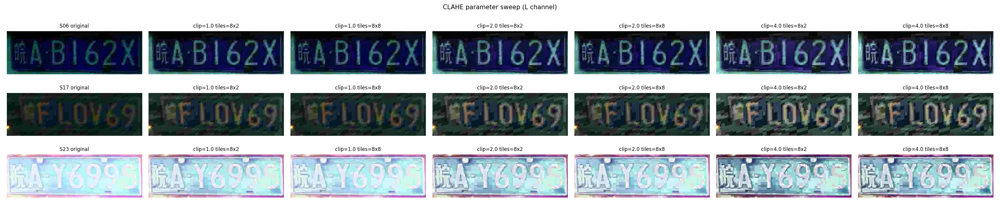

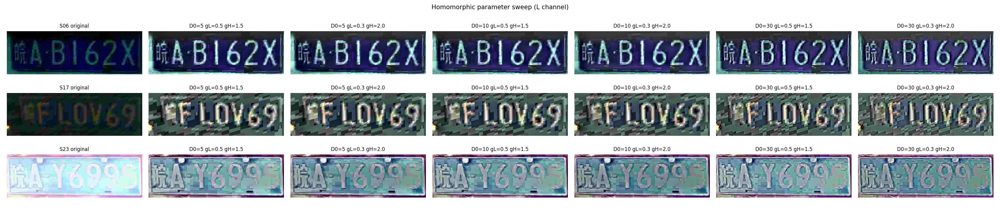

In [6]:
display(Image(os.path.join(R, 'figures/sweep_clahe.png'), width=1100))
display(Image(os.path.join(R, 'figures/sweep_homomorphic.png'), width=1100))

## 5. Evaluation – OCR Character Error Rate
* Engine: **Tesseract 5.5.4**, `chi_sim` (tessdata_fast), `--oem 1 --psm 8`, character whitelist (31 province characters + 24 letters + 10 digits), grayscale input. Identical for all methods.
* OCR settings were selected on a **separate calibration set** of 20 CCPD-DB images (seed 7, disjoint from the 50 test images) using only unprocessed crops (grid in `ocr_calibration_grid.csv`). Four settings tied at CER 0.507; tie broken by zero empty outputs and native resolution.
* Ground truth: plate indices in the CCPD filename decoded with the official `provinces` / `alphabets` / `ads` tables.
* Normalisation: upper-case; keep only CJK ideographs, A–Z, 0–9 (drops spaces and the '·' separator).
* **CER = Σ Levenshtein(OCR, GT) / Σ |GT|** over all images of the subset. `CER_alnum_6` ignores the Chinese province character.
* 95 % CI of ΔCER (method − original): paired bootstrap over images, 5000 resamples.

In [7]:
print(open(os.path.join(R, 'ocr_settings.txt')).read())
summ = pd.read_csv(os.path.join(R, 'metrics_summary_ocr.csv'), keep_default_na=False)
display(summ)

tesseract 5.5.4; pytesseract 0.3.13
lang=chi_sim; config: --tessdata-dir "ocr/tessdata" --oem 1 --psm 8 -c tessedit_char_whitelist=皖沪津渝冀晋蒙辽吉黑苏浙京闽赣鲁豫鄂湘粤桂琼川贵云藏陕甘青宁新警学ABCDEFGHJKLMNPQRSTUVWXYZ0123456789
Input: 440x140 crop of each method, converted BGR->GRAY (cv2), no other preprocessing.



,subset,method,n_images,CER_full,CER_alnum_6,exact_match,empty_outputs,imgs_better_than_orig,imgs_same_as_orig,imgs_worse_than_orig,dCER_vs_orig_95CI
0,all,original,50,0.6200,0.5633,0,3,,,,
1,all,clahe,50,0.6057,0.5467,0,2,9,33,8,"[-0.049, +0.017]"
2,all,clahe_tophat,50,0.6629,0.6100,0,3,10,23,17,"[-0.003, +0.091]"
3,all,homomorphic,50,0.6143,0.5667,0,2,14,25,11,"[-0.054, +0.046]"
4,group=dark,original,20,0.5571,0.4917,0,1,,,,
5,group=dark,clahe,20,0.5429,0.4833,0,1,3,14,3,
6,group=dark,clahe_tophat,20,0.5857,0.5167,0,0,3,11,6,
7,group=dark,homomorphic,20,0.5000,0.4417,0,0,7,10,3,
8,group=mid,original,10,0.4571,0.3833,0,0,,,,
9,group=mid,clahe,10,0.4143,0.3167,0,0,3,6,1,


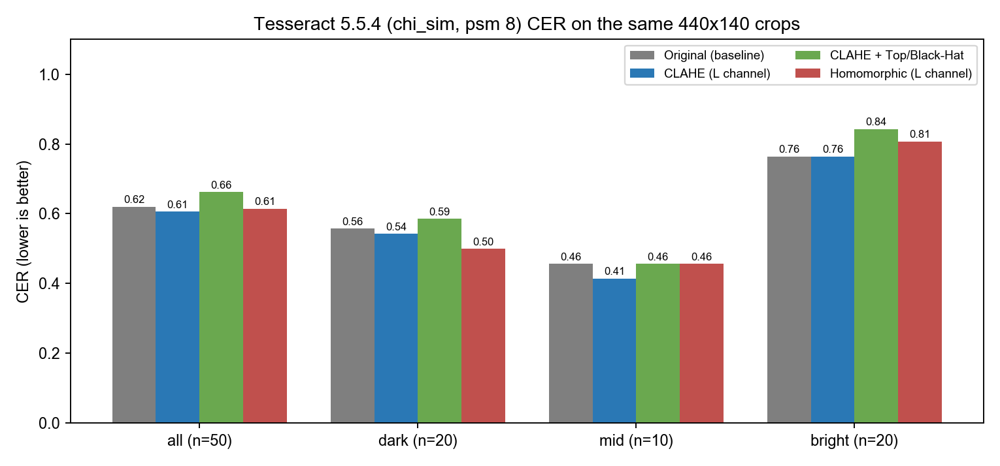

In [8]:
display(Image(os.path.join(R, 'figures/cer_by_group.png'), width=900))

In [9]:
ocr = pd.read_csv(os.path.join(R, 'ocr_results_per_image.csv'), keep_default_na=False)
piv = ocr.pivot(index='id', columns='method', values='edit_dist')[['original', 'clahe', 'clahe_tophat', 'homomorphic']]
piv['group'] = ocr.drop_duplicates('id').set_index('id').group
display(piv)

method,original,clahe,clahe_tophat,homomorphic,group
id,,,,,
S01,2,2,2,2,dark
S02,4,3,4,3,dark
S03,7,7,6,7,dark
S04,5,3,4,4,dark
S05,7,7,7,6,dark
S06,1,1,2,1,dark
S07,1,1,2,2,dark
S08,7,7,7,5,dark
S09,6,4,5,6,dark


## 6. Auxiliary image measures (descriptive only – not evidence of OCR performance)

In [10]:
aux = pd.read_csv(os.path.join(R, 'metrics_aux_per_image.csv'))
cols = ['L_mean', 'local_contrast', 'illum_cv', 'sat_hi_frac', 'sat_lo_frac', 'chroma_shift']
display(aux.groupby(['group', 'method'])[cols].mean().round(3))
print('Top/Black-Hat: mean stroke estimate %.1f px, mean clipped fraction %.1f %%' %
      (aux.diag_stroke_px.mean(), 100 * aux.diag_tophat_clip_frac.mean()))
print('Homomorphic NaN/Inf pixels in total:', int(aux.diag_nan_or_inf.sum()))

L_mean  local_contrast  illum_cv  sat_hi_frac  sat_lo_frac  chroma_shift
group  method                                                                                 
bright clahe         196.508          21.556     0.149        0.044        0.000         0.181
       clahe_tophat  190.983          35.790     0.158        0.167        0.021         0.893
       homomorphic   163.477          21.962     0.093        0.006        0.004         0.325
       original      220.168          13.192     0.101        0.105        0.000         0.000
dark   clahe          36.152          18.166     0.341        0.000        0.134         0.187
       clahe_tophat   45.631          35.412     0.347        0.009        0.276         0.554
       homomorphic    67.126          30.493     0.146        0.005        0.012         0.172
       original       17.380           9.254     0.374        0.000        0.230         0.000
mid    clahe          52.657          21.407     0.246        0.000        0.017         0.182
       clahe_tophat   63.038          41.345     0.251        0.022        0.154         0.727
       homomorphic    81.156          33.091     0.132        0.005        0.009         0.196
       original       28.237          10.660     0.259        0.000        0.059         0.000

Top/Black-Hat: mean stroke estimate 8.7 px, mean clipped fraction 18.1 %
Homomorphic NaN/Inf pixels in total: 0


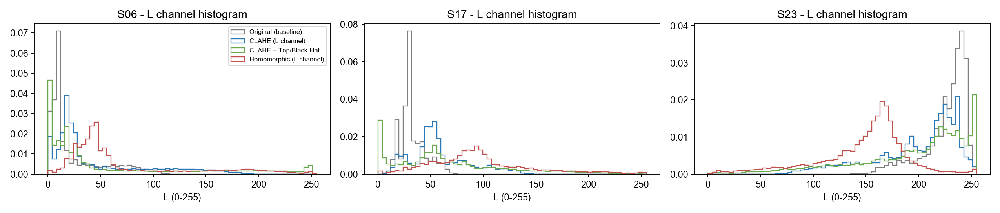

In [11]:
display(Image(os.path.join(R, 'figures/luminance_histograms.png'), width=1100))

## 7. Successful, unchanged and failed examples
Selection rule: largest per-image change of OCR edit distance vs. the original (per method / group), plus cases where all variants are identical. Observations in `review/visual_review.csv` are based only on what is visible in the panels.

,id,category,method_focus,selection_reason,visual_observation
0,S39,success,homomorphic,largest CER decrease of any method in group da...,Very dark plate (CCPD brightness 21). Homomorp...
1,S15,success,all,all three methods reduce edit distance (4 -> 2...,Dim yellowish plate. All methods raise charact...
2,S45,success,clahe,largest CER decrease in group bright (edit dis...,Glare-washed plate. CLAHE restores local contr...
3,S18,unchanged,all,identical OCR for all four variants,Original is already well exposed and readable....
4,S49,unchanged,all,CER 1.00 for all four variants,Whole plate is overexposed: white characters o...
5,S14,failure,clahe_tophat+homomorphic,largest CER increase (edit distance 3 -> 7) in...,Dark plate with strong JPEG blocking. Top/Blac...
6,S26,failure,clahe_tophat+homomorphic,Top/Black-Hat edit distance 3 -> 7; Homomorphi...,Bright plate. Top/Black-Hat produces dark halo...
7,S10,failure,homomorphic,Homomorphic edit distance 5 -> 7 on the darkes...,Extremely dark plate. Homomorphic normalisatio...


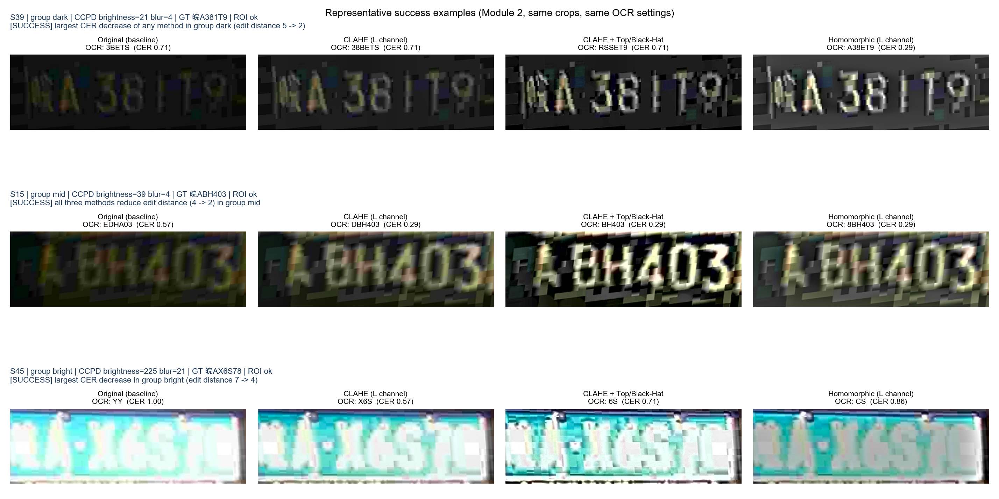

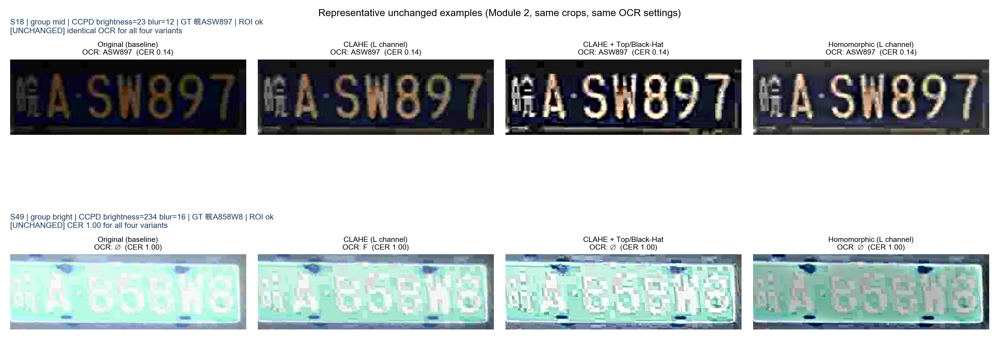

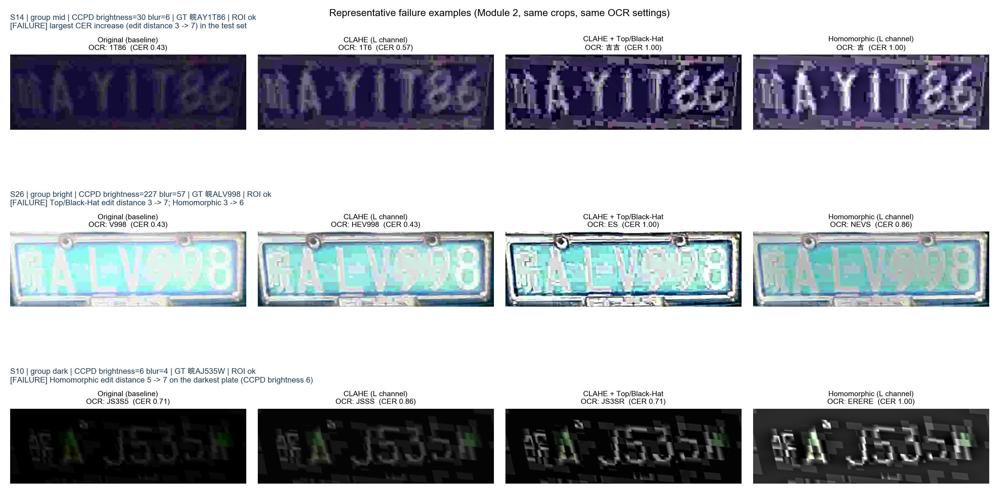

In [12]:
rv = pd.read_csv(os.path.join(PROJECT, 'review/visual_review.csv'))
display(rv)
for cat in ['success', 'unchanged', 'failure']:
    display(Image(os.path.join(R, f'figures/representative_{cat}.png'), width=1100))

## 8. Findings and limitations
* **Overall (n = 50)** no method gives a statistically clear OCR improvement: CLAHE 0.606 and Homomorphic 0.614 vs. original 0.620 (both CIs include 0). CLAHE + Top/Black-Hat is worse (0.663, CI [−0.003, +0.091]).
* **Dark plates (n = 20):** Homomorphic has the lowest CER (0.500 vs 0.557) and strongly reduces illumination non-uniformity (illum_cv 0.374 → 0.146).
* **Bright/glare plates (n = 20):** nothing helps; saturated (clipped) characters cannot be recovered and Homomorphic/Top-Hat add haze or halos.
* **Main failure causes (visual):** saturation from glare, JPEG 8×8 block amplification in very dark crops, halos from Top/Black-Hat, low resolution (S02/S04 upsampled 3×).
* **OCR limitation:** Tesseract is a general document OCR; it almost never reads the Chinese province character and has 0/50 exact matches. CER differences are therefore small and partly reflect OCR behaviour, not only image quality.
* Crops come from CCPD annotations (temporary rectification), not Module 1. Small sample (50), single dataset (CCPD-DB), parameters chosen visually on 3 crops of the test set.
* No deep-learning model was used in Module 2.

## 9. Re-running
```bash
.venv/bin/python src/run_pipeline.py --out results_rerun --stages roi,enhance,sweep,ocr,metrics,figures,calibrate
```
The runner refuses to overwrite existing files, so always use a new `--out` folder.